In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config as C
from src.data_loader import load_raw

pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

### Data Understanding

In [2]:
raw = load_raw()

In [3]:
raw.head()

,Customer_ID,Age,Gender,Location,Tenure_Months,Monthly_Charges,Total_Charges,Subscription_Type,Payment_Method,Login_Frequency,Support_Tickets,Complaints,Discount_Received,Contract_Type,Last_Login_Days,Usage_Hours,Customer_Satisfaction,Churn
0,CUST104939,27.0,Female,Ahmedabad,12,1106.24,12694.02,Premium,Debit Card,16,1,0,0,Month-to-Month,10,46.7,4.0,0
1,CUST108673,52.0,Male,Hyderabad,17,621.18,62.12,Standard,UPI,13,1,1,20,Month-to-Month,12,45.4,5.0,0
2,CUST103277,18.0,Male,?,31,297.43,9149.23,Basic,UPI,14,3,1,5,Month-to-Month,11,19.4,4.0,1
3,CUST105552,45.0,Other,Kolkata,26,594.26,14894.33,Standard,UPI,6,4,3,0,Month-to-Month,8,NaN,1.0,0
4,CUST108857,49.0,Female,Mumbai,28,570.39,15385.08,Standard,Debit Card,10,0,0,5,One Year,23,26.4,4.0,0


In [4]:
print("records, features:", raw.shape)

records, features: (10070, 18)


In [5]:
print("duplicate rows:", raw.duplicated().sum(), "| repeated Customer_IDs:", raw["Customer_ID"].duplicated().sum())

duplicate rows: 60 | repeated Customer_IDs: 70


In [6]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10070 entries, 0 to 10069
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            10070 non-null  str    
 1   Age                    9060 non-null   str    
 2   Gender                 10070 non-null  str    
 3   Location               10070 non-null  str    
 4   Tenure_Months          10070 non-null  int64  
 5   Monthly_Charges        10070 non-null  float64
 6   Total_Charges          9103 non-null   str    
 7   Subscription_Type      10070 non-null  str    
 8   Payment_Method         9971 non-null   str    
 9   Login_Frequency        10070 non-null  int64  
 10  Support_Tickets        10070 non-null  int64  
 11  Complaints             10070 non-null  int64  
 12  Discount_Received      10070 non-null  int64  
 13  Contract_Type          10070 non-null  str    
 14  Last_Login_Days        10070 non-null  int64  
 15  Usage_Hours  

In [7]:
print("Missing values (NaN):")
print(raw.isna().sum()[raw.isna().sum() > 0].to_string())

Missing values (NaN):
Age                      1010
Total_Charges             967
Payment_Method             99
Usage_Hours              1008
Customer_Satisfaction    1006


In [8]:
print(
    "\nNumeric-looking columns stored as String:", 
    [c for c in ["Age", "Total_Charges"] if raw[c].dtype != float and raw[c].dtype != int]
)

raw.describe().T[["min", "max"]]


Numeric-looking columns stored as String: ['Age', 'Total_Charges']


,min,max
Tenure_Months,-3.0,500.0
Monthly_Charges,-599.0,59900.0
Login_Frequency,0.0,28.0
Support_Tickets,-2.0,40.0
Complaints,0.0,7.0
Discount_Received,-10.0,100.0
Last_Login_Days,-1.0,92.0
Usage_Hours,-10.0,2400.0
Customer_Satisfaction,0.0,10.0
Churn,0.0,1.0


In [9]:
# hidden missing values
raw.isin(["", " ", "?", "N/A", "Unknown", -1]).sum()

Customer_ID                0
Age                        0
Gender                    92
Location                  96
Tenure_Months              0
Monthly_Charges            0
Total_Charges            302
Subscription_Type          0
Payment_Method             0
Login_Frequency            0
Support_Tickets            0
Complaints                 0
Discount_Received          0
Contract_Type              0
Last_Login_Days          100
Usage_Hours                0
Customer_Satisfaction      0
Churn                      0
dtype: int64

In [10]:
raw[raw["Customer_ID"].duplicated(keep=False)].sort_values("Customer_ID").head(10)

,Customer_ID,Age,Gender,Location,Tenure_Months,Monthly_Charges,Total_Charges,Subscription_Type,Payment_Method,Login_Frequency,Support_Tickets,Complaints,Discount_Received,Contract_Type,Last_Login_Days,Usage_Hours,Customer_Satisfaction,Churn
22,CUST100052,21.0,Female,Kolkata,35,340.07,"₹11,847.74",Basic,Credit Card,9,0,0,20,One Year,1,7.1,5.0,0
6657,CUST100052,21.0,Female,Kolkata,35,340.07,"₹11,847.74",Basic,Credit Card,9,0,0,20,One Year,1,7.1,5.0,0
159,CUST100270,29.0,Female,Chennai,8,318.73,2381.44,Basic,UPI,8,1,1,5,Month-to-Month,3,18.6,4.0,0
7840,CUST100270,29.0,Female,Chennai,8,318.73,2381.44,Basic,UPI,8,1,1,5,Month-to-Month,3,18.6,4.0,0
8327,CUST100403,NaN,Female,MUMBAI,32,338.03,10582.84,Basic,Credit Card,14,2,0,10,Month-to-Month,2,26.8,4.0,0
110,CUST100403,NaN,Female,MUMBAI,32,338.03,10582.84,Basic,Credit Card,14,2,0,10,Month-to-Month,2,26.8,4.0,0
7518,CUST100415,40.0,Male,Mumbai,17,326.70,5325.48,Basic,upi,11,2,1,0,Month-to-Month,7,62.3,4.0,0
2134,CUST100415,40.0,Male,Mumbai,17,326.70,5325.48,Basic,upi,11,1,1,0,Month-to-Month,7,62.3,4.0,0
6429,CUST100507,43.0,Female,AHMEDABAD,6,303.01,1689.95,Basic,UPI,14,2,1,5,One Year,2,19.8,NaN,0
41,CUST100507,43.0,Female,AHMEDABAD,6,303.01,1689.95,Basic,UPI,14,2,1,5,One Year,2,19.8,NaN,0


In [11]:
# Checking Outliers
temp = raw.copy()

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum()

for c in temp.select_dtypes("number").columns.drop("Churn"):
    print(c, iqr_outliers(temp[c]))

Tenure_Months 6
Monthly_Charges 10
Login_Frequency 98
Support_Tickets 635
Complaints 512
Discount_Received 4
Last_Login_Days 431
Usage_Hours 284
Customer_Satisfaction 51


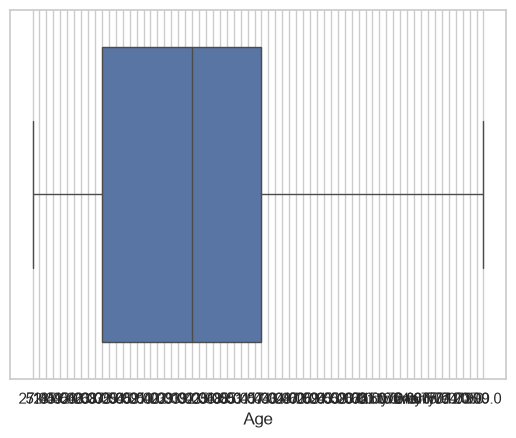

In [12]:
sns.boxplot(x=temp["Age"]) 
plt.show()

- Which features could influence churn ?

In [13]:
# Categorical features: churn rate per group
for c in ["Contract_Type", "Subscription_Type", "Payment_Method", "Gender", "Location"]:
    print(temp.groupby(c)["Churn"].mean().sort_values(), "\n")

Contract_Type
two year            0.000000
TWO YEAR            0.000000
 Two Year           0.032258
Two Year            0.044099
one year            0.062500
 One Year           0.074627
ONE YEAR            0.081967
2 Year              0.083333
One Year            0.101918
1 Year              0.140000
 Month-to-Month     0.148515
month-to-month      0.196970
MONTH-TO-MONTH      0.222222
Month-to-Month      0.225603
Month to Month      0.270270
Name: Churn, dtype: float64 

Subscription_Type
standard      0.090909
 Standard     0.102564
 Basic        0.131148
Basic         0.139937
BASIC         0.145455
Standard      0.162379
basic         0.169492
PREMIUM       0.171429
premium       0.175000
Premium       0.185326
STANDARD      0.192982
 Premium      0.333333
Name: Churn, dtype: float64 

Payment_Method
 N/A             0.000000
 Debit Card      0.058824
upi              0.075758
NetBanking       0.100000
Upi              0.129032
NET BANKING      0.136364
 Wallet          0.142857


In [14]:
# Numeric features: average value for churned vs retained customers
temp.groupby("Churn")[["Tenure_Months", "Last_Login_Days", "Login_Frequency", "Complaints", "Customer_Satisfaction", "Monthly_Charges"]].mean()

,Tenure_Months,Last_Login_Days,Login_Frequency,Complaints,Customer_Satisfaction,Monthly_Charges
Churn,,,,,,
0,31.238314,8.375826,13.061261,0.678234,3.738413,606.531288
1,24.192741,11.038798,12.056946,1.167710,3.341515,649.976083


In [15]:
# Correlation with churn
temp.select_dtypes("number").corr()["Churn"].sort_values()

Customer_Satisfaction   -0.183604
Tenure_Months           -0.132033
Login_Frequency         -0.096000
Discount_Received       -0.053400
Usage_Hours             -0.018090
Monthly_Charges          0.011677
Support_Tickets          0.101810
Last_Login_Days          0.109856
Complaints               0.194277
Churn                    1.000000
Name: Churn, dtype: float64

### Data Cleaning

In [16]:
from src.preprocessing import clean_data

df_clean, log = clean_data(raw)
print(pd.Series(log).to_string())

rows_raw                         10070
invalid_Age                         15
invalid_Tenure_Months               12
invalid_Monthly_Charges             12
invalid_Usage_Hours                  9
invalid_Customer_Satisfaction       20
invalid_Support_Tickets              8
invalid_Discount_Received           10
invalid_Login_Frequency              0
invalid_Last_Login_Days            100
invalid_Complaints                   0
exact_duplicates                    60
repeated_ids                        10
illogical_total_charges            102
rows_clean                       10000
remaining_nan                        0


In [17]:
print("NaN left:", df_clean.isna().sum().sum(), "| duplicate IDs:", df_clean["Customer_ID"].duplicated().sum())

NaN left: 0 | duplicate IDs: 0


In [18]:
df_clean.describe().T[["min", "max"]]

,min,max
Age,18.0,75.0
Tenure_Months,1.0,72.0
Monthly_Charges,269.11,1148.84
Total_Charges,262.81,80425.04
Login_Frequency,0.0,28.0
Support_Tickets,0.0,8.0
Complaints,0.0,7.0
Discount_Received,0.0,25.0
Last_Login_Days,0.0,92.0
Usage_Hours,0.0,135.6


In [19]:
df_clean.to_csv("../data/processed/customer_churn_clean.csv", index=False)

### Exploratory Data Analysis

In [20]:
from src.feature_engineering import add_features

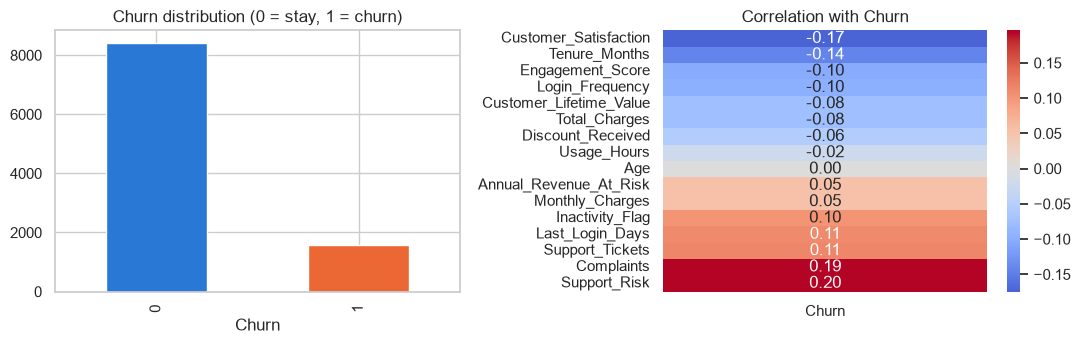

overall churn rate 15.8%


In [21]:
df = add_features(df_clean)

overall = df["Churn"].mean()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

df["Churn"].value_counts().sort_index().plot.bar(ax=ax[0], color=[C.BLUE, C.ORANGE])

ax[0].set_title("Churn distribution (0 = stay, 1 = churn)")

sns.heatmap(
    df.select_dtypes("number").corr()[["Churn"]].drop("Churn").sort_values("Churn"), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1]
)
ax[1].set_title("Correlation with Churn")

plt.tight_layout(); plt.show(); print(f"overall churn rate {overall:.1%}")

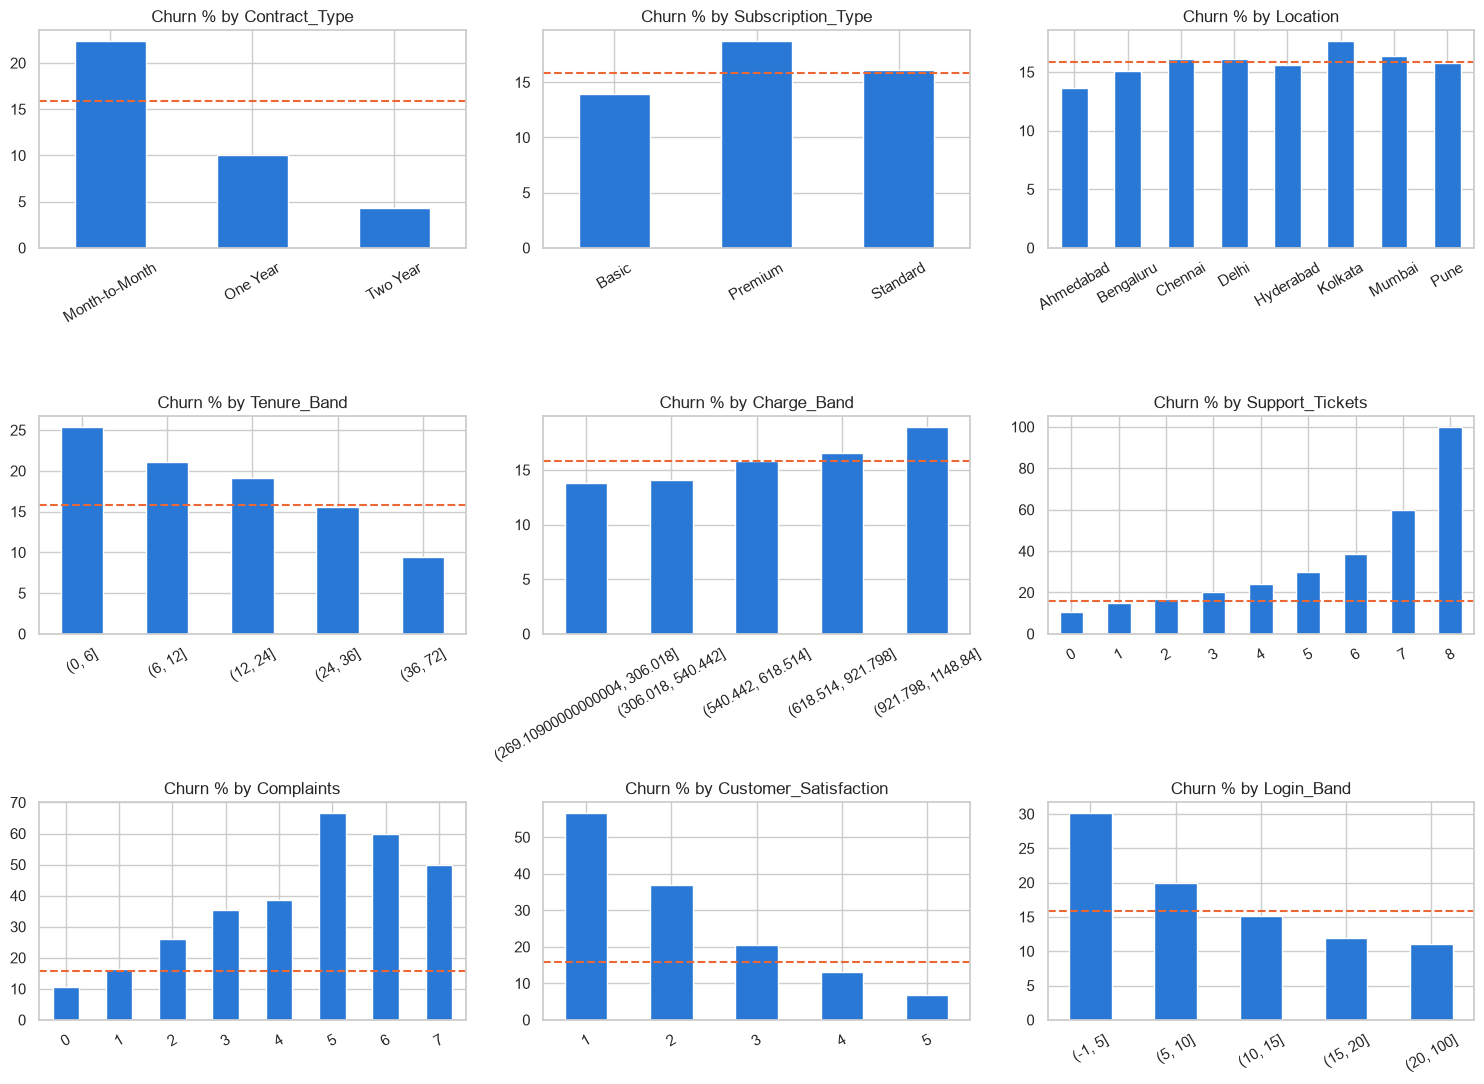

In [22]:
df["Tenure_Band"] = pd.cut(df["Tenure_Months"], [0, 6, 12, 24, 36, 72])

df["Charge_Band"] = pd.qcut(df["Monthly_Charges"], 5)

df["Login_Band"] = pd.cut(df["Login_Frequency"], [-1, 5, 10, 15, 20, 100])

panels = ["Contract_Type", "Subscription_Type", "Location", "Tenure_Band", "Charge_Band", "Support_Tickets", "Complaints", "Customer_Satisfaction", "Login_Band"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))

for ax, c in zip(axes.ravel(), panels):
    r = (df.groupby(c, observed=True)["Churn"].mean() * 100)
    r.plot.bar(ax=ax, color=C.BLUE)
    ax.axhline(overall * 100, color=C.ORANGE, ls="--")
    ax.set_title(f"Churn % by {c}"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Customer Behavior Analysis

In [23]:
from src.feature_engineering import add_warning_signals, customer_based_group_analysis

df = add_warning_signals(df)

df["Customer_Risk_Group"] = customer_based_group_analysis(df["Warning_Signals"])

df.groupby("Customer_Risk_Group")["Churn"].agg(actual_churn_rate="mean", customers="count").reindex(["Low", "Medium", "High"]).round(3)

,actual_churn_rate,customers
Customer_Risk_Group,,
Low,0.102,4269
Medium,0.178,5169
High,0.404,562


### Feature Engineering

In [24]:
print(df[["Customer_Lifetime_Value", "Engagement_Score", "Support_Risk", "Inactivity_Flag", "Churn"]].corr()["Churn"].round(3))

Customer_Lifetime_Value   -0.077
Engagement_Score          -0.103
Support_Risk               0.196
Inactivity_Flag            0.103
Churn                      1.000
Name: Churn, dtype: float64


In [25]:
df[["Monthly_Charges", "Tenure_Months", "Customer_Lifetime_Value", "Engagement_Score", "Support_Risk", "Inactivity_Flag"]].head()

,Monthly_Charges,Tenure_Months,Customer_Lifetime_Value,Engagement_Score,Support_Risk,Inactivity_Flag
0,1148.12,16,18369.92,55.7,8,1
1,331.28,31,10269.68,56.2,4,0
2,1107.48,28,31009.44,68.5,1,0
3,953.48,26,24790.48,53.9,0,1
4,601.22,29,17435.38,39.5,1,0


###  Categorical Data Encoding

In [26]:
from src.preprocessing import make_preprocessor

prep = make_preprocessor(scale=True).fit(df[C.ALL_FEATURES])
names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
print(len(C.ALL_FEATURES), "input columns ->", len(names), "model columns") 
print(names)

19 input columns -> 32 model columns
['Age', 'Tenure_Months', 'Monthly_Charges', 'Login_Frequency', 'Support_Tickets', 'Complaints', 'Discount_Received', 'Last_Login_Days', 'Usage_Hours', 'Customer_Satisfaction', 'Customer_Lifetime_Value', 'Engagement_Score', 'Support_Risk', 'Contract_Type', 'Subscription_Type', 'Gender_Female', 'Gender_Male', 'Gender_Other', 'Location_Ahmedabad', 'Location_Bengaluru', 'Location_Chennai', 'Location_Delhi', 'Location_Hyderabad', 'Location_Kolkata', 'Location_Mumbai', 'Location_Pune', 'Payment_Method_Credit Card', 'Payment_Method_Debit Card', 'Payment_Method_Net Banking', 'Payment_Method_UPI', 'Payment_Method_Wallet', 'Inactivity_Flag']


### Feature Scaling

In [27]:
# why scaling matters: Age ~ 40 vs Customer_Lifetime_Value ~ 20,000
before = df[["Age", "Customer_Lifetime_Value"]].describe().loc[["mean", "std"]]
after = pd.DataFrame(prep.transform(df[C.ALL_FEATURES])[:, [0, C.NUMERIC_FEATURES.index("Customer_Lifetime_Value")]], columns=["Age", "Customer_Lifetime_Value"]).describe().loc[["mean", "std"]]
print("BEFORE scaling\n", before.round(1), "\n\nAFTER StandardScaler\n", after.round(2))

BEFORE scaling
        Age  Customer_Lifetime_Value
mean  38.2                  17347.4
std   10.9                  14241.3 

AFTER StandardScaler
       Age  Customer_Lifetime_Value
mean  0.0                     -0.0
std   1.0                      1.0


### Train/Test Split

In [28]:
from src.model_training import split_data

X_train, X_test, y_train, y_test = split_data(df)
print(len(X_train), len(X_test), "| churn rate:", round(y_train.mean(), 3), round(y_test.mean(), 3))

8000 2000 | churn rate: 0.158 0.158


### Machine Learning Models

In [29]:
from src.model_training import get_models, cross_validate_models


models = get_models()
print(cross_validate_models(models, X_train, y_train).round(3))

                     CV_AUC_mean  CV_AUC_std
Model                                       
Logistic Regression        0.770       0.010
Decision Tree              0.720       0.008
Random Forest              0.759       0.010
KNN                        0.704       0.014


### Model Evaluation

In [30]:
from src.model_training import get_baseline
from src.evaluation import comparison_table


fitted = {n: m.fit(X_train, y_train) for n, m in models.items()}
fitted_all = {"Baseline (everyone stays)": get_baseline().fit(X_train, y_train), **fitted}

table = comparison_table(fitted_all, X_test, y_test)
table.astype({"TN": int, "FP": int, "FN": int, "TP": int}).round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,TN,FP,FN,TP
Baseline (everyone stays),0.842,0.000,0.000,0.000,0.500,1683,0,317,0
Logistic Regression,0.696,0.304,0.710,0.425,0.763,1167,516,92,225
Decision Tree,0.640,0.261,0.694,0.379,0.711,1059,624,97,220
Random Forest,0.760,0.345,0.574,0.431,0.751,1338,345,135,182
KNN,0.846,0.655,0.060,0.110,0.713,1673,10,298,19


### Important Business Perspective

In [31]:
from src.evaluation import select_best


best, _ = select_best(table) 
print("Selected:", best)

Selected: Logistic Regression


### Model Comparison

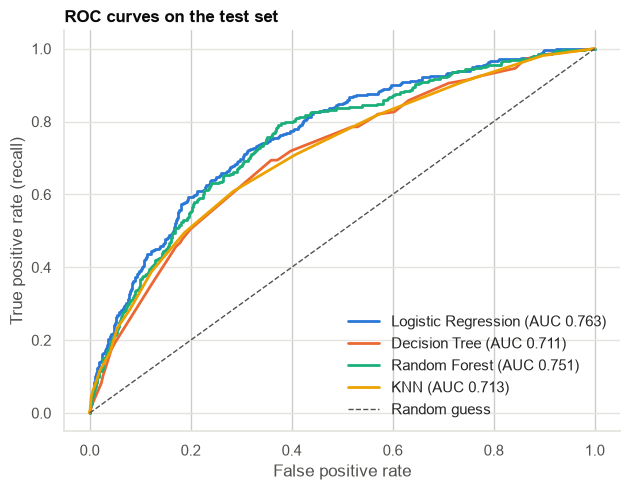

In [32]:
from src.evaluation import fig_roc


fig_roc(fitted, X_test, y_test)
plt.show()

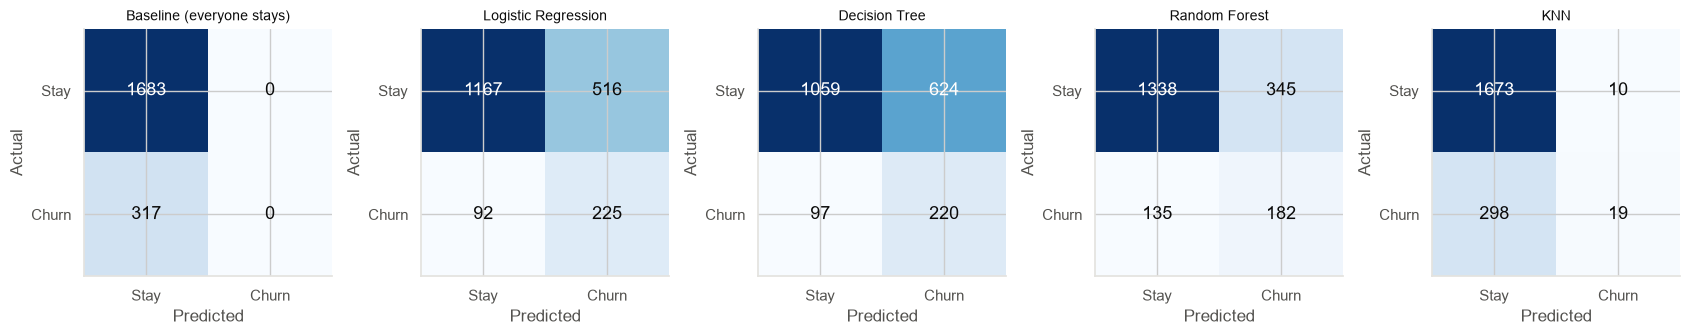

In [33]:
from src.evaluation import fig_confusions


fig_confusions(fitted_all, X_test, y_test)
plt.show()

### Feature Importance

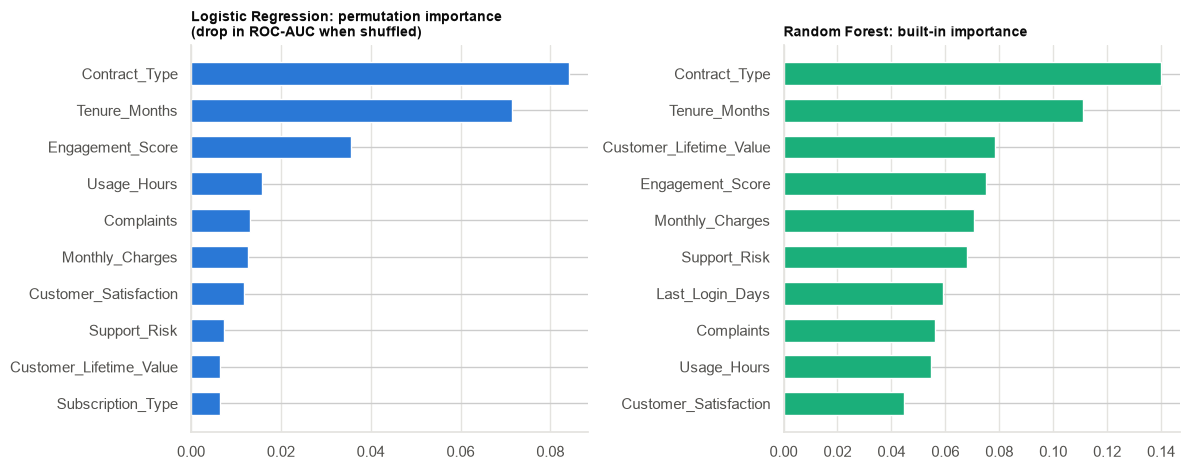

In [34]:
from src.evaluation import importance_tables, fig_importance


imp = importance_tables(fitted, best, X_test, y_test)
fig_importance(imp, best)
plt.show()

In [35]:
imp.get("Logistic Regression (coefficients)", pd.Series(dtype=float)).head(10).round(3)

Contract_Type           -0.967
Tenure_Months           -0.686
Engagement_Score        -0.390
Usage_Hours              0.322
Monthly_Charges          0.272
Customer_Satisfaction   -0.262
Payment_Method_Wallet    0.253
Subscription_Type       -0.244
Complaints               0.224
Location_Ahmedabad      -0.193
dtype: float64

### Customer Risk Scoring

In [36]:
report = pd.read_csv(C.REPORTS_DIR / "customer_risk_report.csv")
print(report["Risk_Level"].value_counts().reindex(["Low", "Medium", "High"]))

Risk_Level
Low       8575
Medium    1372
High        53
Name: count, dtype: int64


### Retention Priority and Business Recommendation Engine

In [37]:
print(report.groupby("Risk_Level").agg(avg_prob=("Churn_Probability", "mean"), actual_churn=("Actual_Churn", "mean")).reindex(["Low", "Medium", "High"]).round(3))
report.head(10)

            avg_prob  actual_churn
Risk_Level                        
Low            0.114         0.113
Medium         0.413         0.421
High           0.769         0.792


,Customer_ID,Churn_Probability,Risk_Level,Customer_Value,Key_Risk_Factor,Retention_Priority,Recommended_Action,Rule_Risk_Group,Actual_Churn
0,CUST104067,0.9469,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
1,CUST103675,0.9300,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,0
2,CUST101446,0.8851,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
3,CUST102143,0.8846,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
4,CUST108501,0.8657,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
5,CUST100656,0.8435,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,Medium,1
6,CUST106493,0.8243,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
7,CUST102396,0.8233,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
8,CUST106652,0.7875,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
9,CUST102206,0.7862,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,0


In [38]:
print(
    report.groupby("Risk_Level").agg(
        customers=("Actual_Churn", "size"), 
        avg_probability=("Churn_Probability", "mean"),
        actual_churn_rate=("Actual_Churn", "mean")) \
            .reindex(["Low", "Medium", "High"]).round(3)
)

print("\nRetention priorities:"); print(report["Retention_Priority"].value_counts().sort_index())
print("\nRule-based group vs ML risk level:")

pd.crosstab(
    report["Rule_Risk_Group"], 
    report["Risk_Level"]
).reindex(index=["Low", "Medium", "High"], columns=["Low", "Medium", "High"]).fillna(0).astype(int)

            customers  avg_probability  actual_churn_rate
Risk_Level                                               
Low              8575            0.114              0.113
Medium           1372            0.413              0.421
High               53            0.769              0.792

Retention priorities:
Retention_Priority
No action     8575
Priority 1      22
Priority 2      16
Priority 3     574
Priority 4     464
Priority 5     349
Name: count, dtype: int64

Rule-based group vs ML risk level:


Risk_Level,Low,Medium,High
Rule_Risk_Group,,,
Low,4130,139,0
Medium,4225,935,9
High,220,298,44


### Model Persistence

In [39]:
import datetime as dt
from src.recommendation import value_cutoffs
from src.model_training import save_artifacts, make_final_pipeline


cut = value_cutoffs(df.loc[X_train.index]) 
X_all, y_all = df[C.ALL_FEATURES], df[C.TARGET]
final = make_final_pipeline(best)

final.fit(X_all, y_all)

raw_cols = [
    c 
    for c in C.ALL_FEATURES 
    if c not in ("Customer_Lifetime_Value", "Engagement_Score", "Support_Risk", "Inactivity_Flag")
]

defaults = {
    c: (float(df[c].median()) if pd.api.types.is_numeric_dtype(df[c]) else str(df[c].mode()[0])) for c in raw_cols
}

best_row = table.loc[best]
meta = {
    "model": best, 
    "trained_at": dt.datetime.now().isoformat(timespec="seconds"),
    "features": C.ALL_FEATURES, 
    "defaults": defaults, 
    "value_cutoffs": cut,
    "test_metrics": {
        k: float(best_row[k]) 
        for k in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
    }
}
save_artifacts(final, meta)
print("saved:", sorted(p.name for p in C.MODELS_DIR.iterdir()))

saved: ['churn_model.pkl', 'metadata.json', 'preprocessing.pkl']


### Prediction System

In [40]:
from src.prediction import predict_customer, load_artifacts


art = load_artifacts() 
print("model:", art["meta"]["model"], "| trained:", art["meta"]["trained_at"])

for c in [
    {"Customer_ID": "C1025", "Tenure_Months": 4, "Monthly_Charges": 999, "Contract_Type": "Month-to-Month", "Support_Tickets": 5, "Complaints": 3, "Usage_Hours": 6, "Customer_Satisfaction": 2, "Last_Login_Days": 40},
    {"Customer_ID": "C1102", "Tenure_Months": 48, "Monthly_Charges": 599, "Contract_Type": "Two Year", "Usage_Hours": 35, "Customer_Satisfaction": 5, "Last_Login_Days": 2}
]:
    print(predict_customer(c, art))

model: Logistic Regression | trained: 2026-11-14T16:48:31
{'Customer_ID': 'C1025', 'Churn_Probability': 0.9244, 'Risk_Level': 'HIGH', 'Customer_Value': 'High', 'Retention_Priority': 'Priority 1', 'Key_Risk_Factor': 'Complaints / support issues', 'Recommended_Action': 'Retention team contact - Customer support intervention'}
{'Customer_ID': 'C1102', 'Churn_Probability': 0.0163, 'Risk_Level': 'LOW', 'Customer_Value': 'Medium', 'Retention_Priority': 'No action', 'Key_Risk_Factor': 'Stable engagement', 'Recommended_Action': 'No action'}


### Customer Risk Report

In [41]:
report.head(10)

,Customer_ID,Churn_Probability,Risk_Level,Customer_Value,Key_Risk_Factor,Retention_Priority,Recommended_Action,Rule_Risk_Group,Actual_Churn
0,CUST104067,0.9469,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
1,CUST103675,0.9300,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,0
2,CUST101446,0.8851,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
3,CUST102143,0.8846,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
4,CUST108501,0.8657,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
5,CUST100656,0.8435,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,Medium,1
6,CUST106493,0.8243,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
7,CUST102396,0.8233,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
8,CUST106652,0.7875,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,1
9,CUST102206,0.7862,High,High,Complaints / support issues,Priority 1,Retention team contact - Customer support inte...,High,0
